# Explainability (Shapley attributions)

`explain()` splits each point forecast into **additive contributions** from windows of the target history and from
known-future exogenous columns. It works on every model by masking parts of the input and re-running the model,
and it uses [`shap`](https://github.com/shap/shap) for the Shapley values. See [Explainability](../explainability.md)
for the full API.

> **Attributions are not causal effects.** They describe how *this model's forecast* reacts when part of its input
> is masked, not what drives the series.

In [ ]:
!UV_CONSTRAINT= UV_BUILD_CONSTRAINT= uv pip install -q "foundationforecast[plot,explain]"

**Dataset:** hourly day-ahead electricity prices for Germany (`DE`), with two known-future covariates
(`ex_1`, `ex_2`). Horizon length is **24 hours** (`h=24`).

The notebook has four parts:

1. **One model**, with history windows and exogenous players, plus a planted-signal check that the attributions
   point at the right inputs.
2. **Several models** with `FoundationForecast.explain()`.
3. **Masking choice:** `mask="nan"` vs `mask="fill"` and how it moves the credit around.
4. **Limits:** what happens when the model reads less context than your history windows.

## Import libraries

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from foundationforecast import FoundationForecast, ShapExplanations
from foundationforecast.models import Chronos, Tafsut, Timestral, Toto

## Load the dataset

In [2]:
df = pd.read_parquet(
    "https://timecopilot.s3.amazonaws.com/public/data/electricity_price/train.parquet"
)
X_df = pd.read_parquet(
    "https://timecopilot.s3.amazonaws.com/public/data/electricity_price/futr_exog.parquet"
)
df = df[df["unique_id"] == "DE"]
X_df = X_df[X_df["unique_id"] == "DE"]
h = 24
df.tail()

,unique_id,ds,y,ex_1,ex_2
103867,DE,2017-12-11 19:00:00,39.680000,27336.50,18116.652344
103868,DE,2017-12-11 20:00:00,40.700001,25954.25,18590.554688
103869,DE,2017-12-11 21:00:00,34.430000,24825.00,18815.535156
103870,DE,2017-12-11 22:00:00,31.950001,23649.00,18973.365234
103871,DE,2017-12-11 23:00:00,27.350000,21941.00,19076.228516


A small helper to plot attributions: for each horizon step, a stacked bar of every player's contribution.
The black line is the forecast minus the baseline (`-shap-base`), which the bars add up to exactly.

In [3]:
def plot_attributions(attr, alias, unique_id, ax=None):
    one = attr[attr["unique_id"] == unique_id].reset_index(drop=True)
    prefix = f"{alias}-shap-"
    parts = [c for c in one.columns if c.startswith(prefix) and c != prefix + "base"]
    if ax is None:
        _, ax = plt.subplots(figsize=(10, 4))
    x = np.arange(len(one))
    up, down = np.zeros(len(one)), np.zeros(len(one))
    for i, col in enumerate(parts):
        v = one[col].to_numpy()
        ax.bar(x, np.clip(v, 0, None), bottom=up, color=f"C{i}", label=col.removeprefix(prefix))
        ax.bar(x, np.clip(v, None, 0), bottom=down, color=f"C{i}")
        up += np.clip(v, 0, None)
        down += np.clip(v, None, 0)
    ax.plot(x, one[alias] - one[prefix + "base"], color="black", lw=1.5, label="forecast - base")
    ax.axhline(0, color="gray", lw=0.5)
    ax.set_xticks(x[::4], one["ds"].dt.strftime("%m-%d %H:%M").iloc[::4], rotation=30)
    ax.set_title(f"{alias}: contributions to the forecast of {unique_id}")
    ax.legend(ncol=6, fontsize=7, loc="upper center", bbox_to_anchor=(0.5, -0.3))
    return ax

## Part 1: one model

Pass `ShapExplanations` as `explanations` when you create the model. It only stores **defaults for `explain()`**:
`forecast()` never computes attributions, so forecasting stays as fast as before.

`history=["1D", "7D"]` cuts the history into three windows measured back from the last observation: the last day
(`hist-1D`), the six days before it (`hist-1D-7D`) and everything older (`hist-older`). With `X_df`, every exogenous
column (`ex_1`, `ex_2`) is also a player. Chronos-2 supports known-future exogenous variables natively.

In [4]:
model = Chronos(
    repo_id="amazon/chronos-2",
    alias="Chronos-2",
    explanations=ShapExplanations(history=["1D", "7D"]),
)
fcst = model.forecast(df=df, h=h, freq="h", X_df=X_df)
fcst.columns.tolist()

['unique_id', 'ds', 'Chronos-2']

The forecast has no attribution columns. `explain()` returns the same forecast plus one column per component.

In [5]:
attr = model.explain(df=df, h=h, freq="h", X_df=X_df)
attr.head()

,unique_id,ds,Chronos-2,Chronos-2-shap-base,Chronos-2-shap-hist-1D,Chronos-2-shap-hist-1D-7D,Chronos-2-shap-hist-older,Chronos-2-shap-ex_1,Chronos-2-shap-ex_2
0,DE,2017-12-12 00:00:00,22.242920,34.731532,-3.888010,-7.531247,0.604844,0.673333,-2.347533
1,DE,2017-12-12 01:00:00,19.525616,34.731532,-5.276750,-8.071408,0.320711,0.739563,-2.918032
2,DE,2017-12-12 02:00:00,17.415367,34.731532,-6.043476,-8.263992,0.114382,0.810908,-3.933986
3,DE,2017-12-12 03:00:00,16.979250,34.731532,-6.223625,-7.604302,-0.179349,1.097597,-4.842603
4,DE,2017-12-12 04:00:00,18.058649,34.731532,-6.245526,-7.207938,0.913742,1.020908,-5.154069


Five players (three history windows and two covariates) means `method="auto"` evaluates every coalition
(`"exact"`): 28 series forecasts. The columns are:

- `Chronos-2`: the point forecast. It is the same as `forecast()`.
- `Chronos-2-shap-base`: the baseline, the mean of the target (the forecast with every player off).
- `Chronos-2-shap-hist-*` and `Chronos-2-shap-ex_*`: the contribution of each player.

For `exact` and `permutation`, the contributions add up to the forecast at every step:

In [6]:
cols = [c for c in attr.columns if "-shap-" in c]
(attr["Chronos-2"] - attr[cols].sum(axis=1)).abs().max()

2.1316282072803006e-14

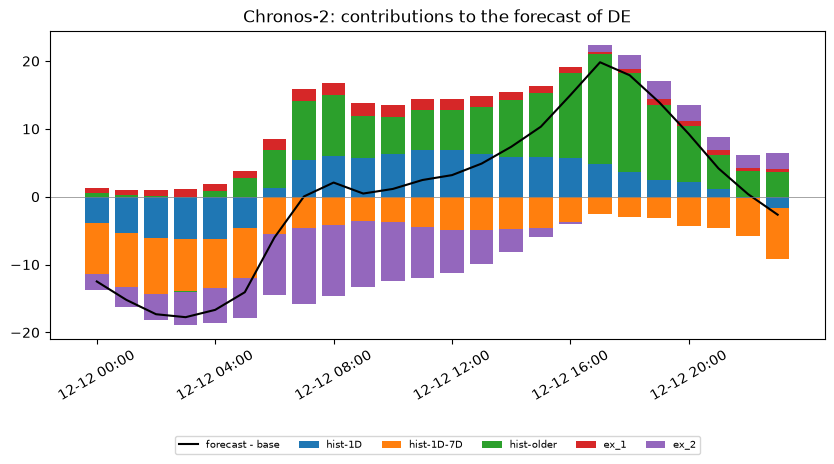

In [7]:
plot_attributions(attr, "Chronos-2", "DE");

Average absolute contribution per player over the horizon:

In [8]:
players = [c for c in cols if not c.endswith("-base")]
attr[players].abs().mean().rename(lambda c: c.removeprefix("Chronos-2-shap-")).round(2).sort_values(ascending=False)

hist-older    6.29
hist-1D-7D    5.22
ex_2          4.71
hist-1D       4.61
ex_1          1.11
dtype: float64

Reading the table: over the horizon, `ex_2` moves this forecast about four times as much as `ex_1`, and the
older history matters at least as much as the last day. These numbers describe **this model on this input**.
They do not say what drives the price (see the note at the top).

### A planted-signal check

How do you know the attributions point at the right inputs? Build a series where you know the answer:
`y` depends on a known-future covariate `signal` and **not** on `noise`, which is pure randomness. A sensible
explanation gives `signal` a large contribution and `noise` almost none.

In [9]:
rng = np.random.default_rng(0)
n = 24 * 60
ds = pd.date_range("2024-01-01", periods=n + h, freq="h")
signal = np.sin(np.arange(n + h) * 2 * np.pi / 24) + 0.5 * rng.normal(size=n + h)
noise = rng.normal(size=n + h)
y = 20 + 5 * signal + 0.2 * rng.normal(size=n + h)

planted = pd.DataFrame(
    {"unique_id": "a", "ds": ds[:n], "y": y[:n], "signal": signal[:n], "noise": noise[:n]}
)
planted_X = pd.DataFrame(
    {"unique_id": "a", "ds": ds[n:], "signal": signal[n:], "noise": noise[n:]}
)
planted_attr = model.explain(df=planted, h=h, freq="h", X_df=planted_X)
planted_players = [
    c for c in planted_attr.columns if "-shap-" in c and not c.endswith("-base")
]
planted_attr[planted_players].abs().mean().rename(lambda c: c.removeprefix("Chronos-2-shap-")).round(2)

hist-1D       0.86
hist-1D-7D    1.11
hist-older    1.14
signal        1.79
noise         0.10
dtype: float64

`signal` gets the largest contribution of all players, and `noise` is close to zero. The history windows
also get some credit because the target's daily pattern is visible in the history too: Shapley values split
credit among **redundant** inputs.

## Part 2: several models

[`FoundationForecast.explain()`][foundationforecast.FoundationForecast.explain] runs `explain()` for every model
and merges the columns on `unique_id` and `ds`. A model uses its own `explanations` unless you pass
`explanations=` to the call, which then applies to **all** models.

Not every model supports known-future exogenous variables, so here we explain the **history only**. Models that treat
`NaN` as missing (Chronos, Tafsut, Timestral, TiRex, Moirai 2) are masked with `NaN`. For the others, such as Toto,
the masked windows are filled with the series baseline.

In [10]:
history_df = df[["unique_id", "ds", "y"]]
models = [
    Chronos(repo_id="amazon/chronos-bolt-tiny", alias="Chronos-Bolt"),
    Tafsut(alias="Tafsut", context_length=512),
    Timestral(repo_id="mistralai/Timestral-5M", alias="Timestral", context_length=512),
    Toto(repo_id="Datadog/Toto-2.0-4m", alias="Toto-2", context_length=512),
]
ff = FoundationForecast(models=models)
multi = ff.explain(
    df=history_df,
    h=h,
    freq="h",
    explanations=ShapExplanations(history=["1D", "7D"]),
)
multi.head()

,unique_id,ds,Chronos-Bolt,Chronos-Bolt-shap-base,Chronos-Bolt-shap-hist-1D,Chronos-Bolt-shap-hist-1D-7D,Chronos-Bolt-shap-hist-older,Tafsut,Tafsut-shap-base,Tafsut-shap-hist-1D,...,Timestral,Timestral-shap-base,Timestral-shap-hist-1D,Timestral-shap-hist-1D-7D,Timestral-shap-hist-older,Toto-2,Toto-2-shap-base,Toto-2-shap-hist-1D,Toto-2-shap-hist-1D-7D,Toto-2-shap-hist-older
0,DE,2017-12-12 00:00:00,23.802673,34.731532,-3.680769,-10.094345,2.846255,24.278671,34.731532,1.358841,...,26.862091,34.731532,1.719253,-9.279947,-0.308747,23.637203,34.731532,-9.929471,-0.167173,-0.997685
1,DE,2017-12-12 01:00:00,22.319530,34.731532,-3.987558,-10.158757,1.734314,22.945694,34.731532,0.406927,...,22.947311,34.731532,-0.390408,-9.677178,-1.716635,20.884914,34.731532,-11.980426,-0.301487,-1.564704
2,DE,2017-12-12 02:00:00,21.124401,34.731532,-4.154922,-10.008315,0.556106,21.902397,34.731532,-0.228353,...,21.496637,34.731532,-1.380866,-9.505744,-2.348285,19.500751,34.731532,-13.324155,-0.497945,-1.408681
3,DE,2017-12-12 03:00:00,20.020817,34.731532,-3.755743,-9.775423,-1.179549,21.208269,34.731532,-0.614685,...,22.665604,34.731532,-1.235284,-7.994972,-2.835672,18.954008,34.731532,-13.861806,0.146874,-2.062592
4,DE,2017-12-12 04:00:00,20.951622,34.731532,-1.559520,-9.604224,-2.616166,22.516502,34.731532,-0.227130,...,24.300951,34.731532,-0.295013,-6.611672,-3.523896,20.403725,34.731532,-12.998129,0.789792,-2.119471


Which masking each model uses (`mask="auto"`):

In [11]:
pd.Series(
    {m.alias: "nan" if m.supports_nan_target else "fill" for m in models}, name="mask"
).to_frame()

,mask
Chronos-Bolt,nan
Tafsut,nan
Timestral,nan
Toto-2,fill


Average contribution per history window, per model (the baseline is shared):

In [12]:
rows = {}
for m in models:
    cols_m = [c for c in multi.columns if c.startswith(f"{m.alias}-shap-hist-")]
    rows[m.alias] = multi[cols_m].mean().rename(lambda c: c.removeprefix(f"{m.alias}-shap-hist-"))
summary = pd.DataFrame(rows).T[["1D", "1D-7D", "older"]]
summary.insert(0, "base", multi["Chronos-Bolt-shap-base"].mean())
summary.round(2)

,base,1D,1D-7D,older
Chronos-Bolt,34.73,6.99,-7.52,4.91
Tafsut,34.73,3.88,-4.98,5.20
Timestral,34.73,5.25,-5.37,5.51
Toto-2,34.73,-1.82,2.70,1.22


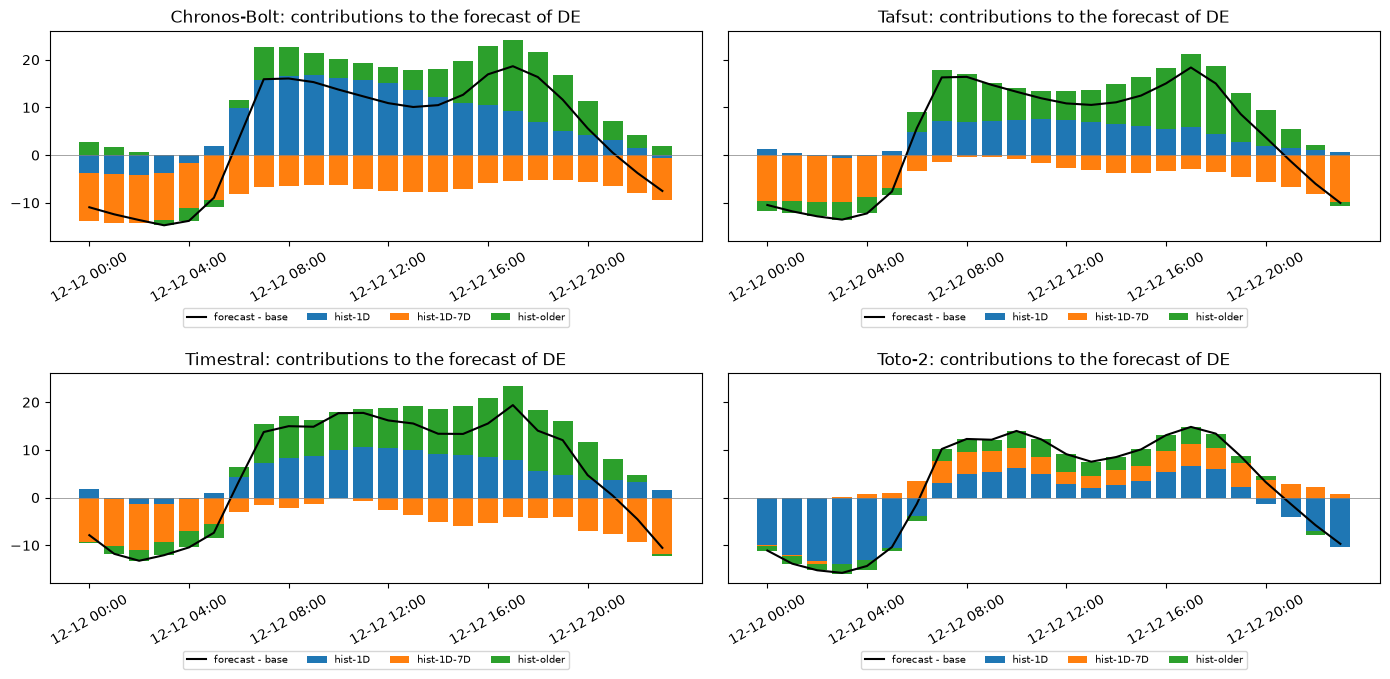

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(14, 7), sharey=True)
for ax, m in zip(axes.ravel(), models):
    plot_attributions(multi, m.alias, "DE", ax=ax)
fig.tight_layout()

Models read their context differently, so the same window can matter more or less depending on the model.
Toto uses `fill` masking while the other three use `nan`, so its numbers are not directly comparable (see Part 3).
Models that sample, such as Toto, also add noise to the differences between coalitions, so small contributions
can be noise.

## Part 3: how a window is switched off

The oldest windows are cut from the start of the context. A window that is switched off but **newer** than one that
is on is masked in place, because the forecast must still start at the last observed timestamp. `mask` controls how:
`"nan"` sets its values to `NaN` and `"fill"` replaces them with the series baseline.

The total is the same either way, but the **credit moves**. Take a series that sits at 10 and jumps by 30 over the
last 3 days, after an old spike at the start:

In [14]:
rng = np.random.default_rng(0)
n = 24 * 30
shift = pd.DataFrame(
    {"unique_id": "a", "ds": pd.date_range("2024-01-01", periods=n, freq="h")}
)
y = 10 + 0.1 * rng.normal(size=n)
y[:100] += 40
y[-72:] += 30
shift["y"] = y

tafsut = Tafsut(alias="Tafsut", context_length=512)
results = {}
for mask in ["nan", "fill"]:
    out = tafsut.explain(
        df=shift,
        h=12,
        freq="h",
        explanations=ShapExplanations(history=["1D", "7D"], mask=mask),
    )
    cols_m = [c for c in out.columns if "-shap-hist-" in c]
    results[mask] = out[cols_m].mean().rename(lambda c: c.removeprefix("Tafsut-shap-hist-"))
pd.DataFrame(results).round(2)

,nan,fill
1D,12.54,21.13
1D-7D,12.07,0.37
older,-3.39,-0.29


With `"nan"`, the last day and days 1 to 7 share the credit, which is what you would expect because the jump
covers both. The ancient spike gets a small contribution. With `"fill"`, almost all of the credit goes to the last day.
Neither is wrong, but they answer slightly different questions:
`"nan"` asks what the model does when the data is missing, `"fill"` asks what it does when the data looks
average. `mask="auto"` picks `"nan"` only for models that handle missing targets.

## Part 4: limits

**Windows the model cannot see get zero attribution.** A window with no observations, or one that lies entirely
beyond the model's `context_length`, cannot change what the model reads. `explain()` reports it as zero and warns.

Here Tafsut reads only the last 20 hours, so with `history=[1, 30]` the window `older` is beyond what it sees:

In [15]:
short_ctx = Tafsut(alias="Tafsut", context_length=20)
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    out = short_ctx.explain(
        df=shift, h=12, freq="h", explanations=ShapExplanations(history=[1, 30])
    )
print(caught[0].message)
cols_m = [c for c in out.columns if "-shap-hist-" in c]
out[cols_m].mean().rename(lambda c: c.removeprefix("Tafsut-shap-hist-")).round(2)

History window(s) ['older'] hold no observations the model can see (they are empty or lie beyond the model's `context_length`), so they get zero attribution. Use smaller history boundaries.


1        10.78
1-30     10.70
older     0.00
dtype: float64

The window `1-30` is still a player: the model reads the 19 hours of it that fall inside its context.

Two things to keep in mind:

- This only works for models that expose a `context_length`. A checkpoint with a **hidden internal cap** is not
  detected, and a window beyond that cap can still pick up credit.
- A shortened context must still be long enough for the model. If masking leaves too little history, the model
  raises its usual error.